# INF-8239 · Ejercicio 06 · VAE, evaluación y Model Card

**Unidad 03 · Modelos generativos (LAB10)**

| Elemento | Definición |
|---|---|
| Datos | Fashion-MNIST (Zalando, licencia MIT), descargado desde el repositorio oficial en un commit fijado |
| Partición | 54 000 entrenamiento / 6 000 validación (estratificada, semilla 42) / 10 000 prueba oficial |
| Modelos | AE (línea base) y VAE con la misma arquitectura densa; latentes de 2 y 16 dimensiones |
| Evaluación | Reconstrucción (BCE, MSE, SSIM), muestreo, interpolación, fidelidad y diversidad (Fréchet, precisión/recall k-NN, entropía de clases), memorización (vecino más cercano) y costo |
| Decisión | Menor distancia de Fréchet en validación entre los modelos que no memorizan |

> Las muestras sintéticas no son datos "privados" por el solo hecho de ser generadas: se mide explícitamente su cercanía al entrenamiento.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json

import pandas as pd
from IPython.display import Image, display

REPORTS = ROOT / "reports"
print("Raíz:", ROOT)

Raíz: /tmp/gen/INF8239_U03_E06_VAE


## 1. Datos reproducibles

In [2]:
from scripts import download_data, train_ae_vae, update_model_card

assert download_data.main() == 0
json.loads((ROOT / "data/raw_manifest.json").read_text())

I0000 00:00:1791400622.130195    2266 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791400622.130866    2266 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1791400623.546205    2266 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791400623.546619    2266 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


OK  train-images-idx3-ubyte.gz  3aede38d61863908…
OK  train-labels-idx1-ubyte.gz  a04f17134ac03560…
OK  t10k-images-idx3-ubyte.gz  346e55b948d973a9…
OK  t10k-labels-idx1-ubyte.gz  67da17c76eaffca5…


{'dataset': 'Fashion-MNIST',
 'license': 'MIT',
 'commit': 'b2617bb6d3ffa2e429640350f613e3291e10b141',
 'files': [{'file': 'data/raw/train-images-idx3-ubyte.gz',
   'url': 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/b2617bb6d3ffa2e429640350f613e3291e10b141/data/fashion/train-images-idx3-ubyte.gz',
   'sha256': '3aede38d61863908ad78613f6a32ed271626dd12800ba2636569512369268a84'},
  {'file': 'data/raw/train-labels-idx1-ubyte.gz',
   'url': 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/b2617bb6d3ffa2e429640350f613e3291e10b141/data/fashion/train-labels-idx1-ubyte.gz',
   'sha256': 'a04f17134ac03560a47e3764e11b92fc97de4d1bfaf8ba1a3aa29af54cc90845'},
  {'file': 'data/raw/t10k-images-idx3-ubyte.gz',
   'url': 'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/b2617bb6d3ffa2e429640350f613e3291e10b141/data/fashion/t10k-images-idx3-ubyte.gz',
   'sha256': '346e55b948d973a97e58d2351dde16a484bd415d4595297633bb08f03db6a073'},
  {'file': 'data/raw

## 2. Entrenamiento y evaluación
*En CPU tarda varios minutos (cuatro modelos y un clasificador de características).*

In [3]:
results = train_ae_vae.run(epochs=15)
update_model_card.main()
print("Seleccionado:", results["selected_model"])
print("Regla:", results["selection_rule"])
print("Exactitud del clasificador de características:", round(results["classifier_test_accuracy"], 4))
results["split"]

E0000 00:00:1791400625.336667    2266 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/15


E0000 00:00:1791400626.012271    2266 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


211/211 - 5s - 22ms/step - loss: 310.1866 - val_loss: 274.9357


Epoch 2/15


...

E0000 00:00:1791401095.816227    2266 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1791401104.069042    2266 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1791401109.079348    2266 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


MODEL_CARD.md actualizado
Seleccionado: ae_z16
Regla: menor distancia de Fréchet en validación entre modelos con ≤ 2 % de muestras más cercanas al entrenamiento que el percentil 1 de imágenes reales de prueba
Exactitud del clasificador de características: 0.8873


{'train': 54000,
 'valid': 6000,
 'test': 10000,
 'valid_fraction': 0.1,
 'seed': 42,
 'limit': 0,
 'train_index_sha256': 'f21e3d1771bfb0627b1aaf3ba7ea18691aaf02bb95dea0af96bbb17bdc62bb46',
 'valid_index_sha256': '1c91db52df669a30ed1bf910acc6a6db7055a02912255a45ef407d514f51f803'}

### 2.1 Curvas y costo

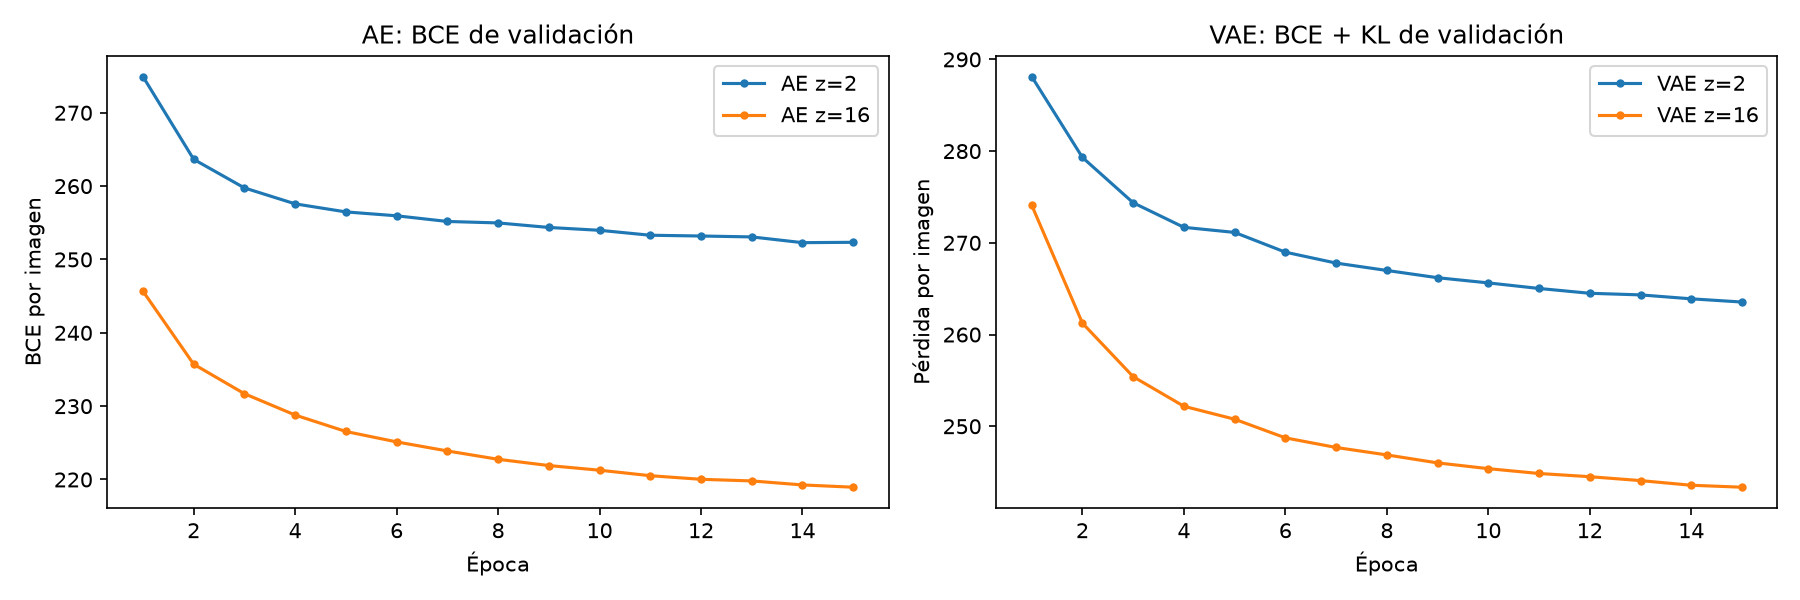

,model,latent_dim,parameters,decoder_parameters,decoder_kb,epochs_run,train_seconds,seconds_per_epoch
0,ae_z2,2,469010,234896,940.27,15,81.55,5.44
1,ae_z16,16,472608,236688,947.28,15,76.68,5.11
2,vae_z2,2,469268,234896,940.29,15,76.68,5.11
3,vae_z16,16,474672,236688,947.29,15,74.79,4.99


In [4]:
display(Image(REPORTS / "fig_learning_curves.png", width=900))
results["cost"].round(2)

## 3. Reconstrucción

,model,bce,mse,ssim,classifier_agreement,kl,elbo_bce_plus_kl,active_dims
0,ae_z2,252.744705,0.0270,0.5153,0.6097,NaN,NaN,NaN
1,ae_z16,219.811005,0.0123,0.6938,0.7945,NaN,NaN,NaN
2,vae_z2,256.242615,0.0284,0.4978,0.5823,6.2954,262.538,2.0
3,vae_z16,226.870407,0.0154,0.6451,0.7430,13.3947,240.265,10.0


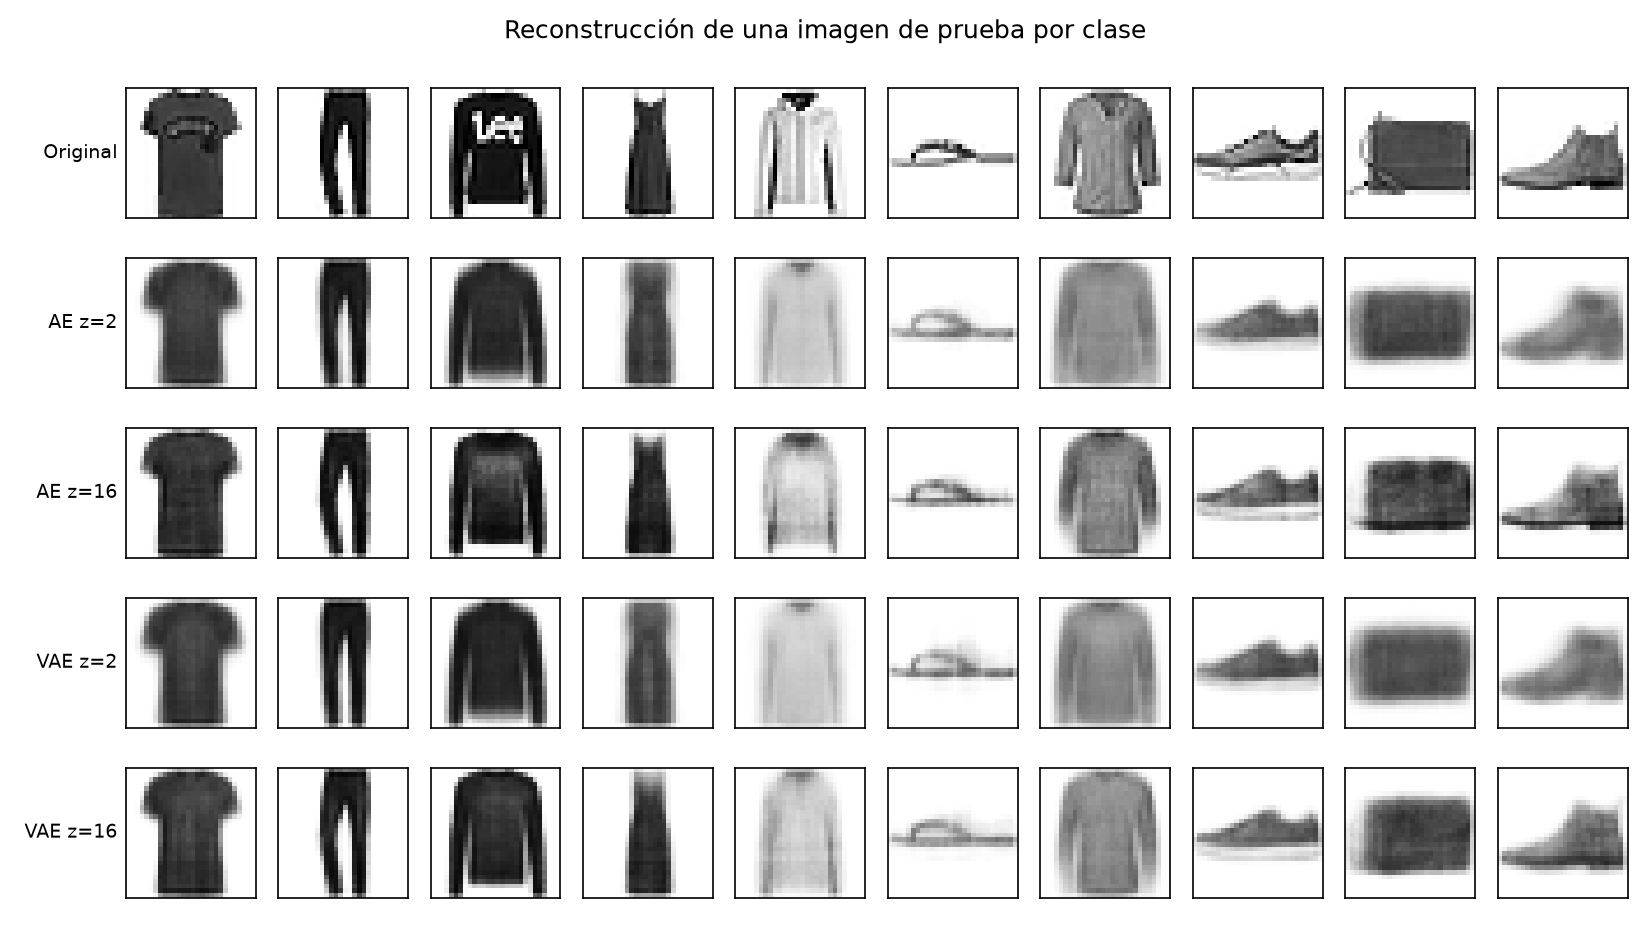

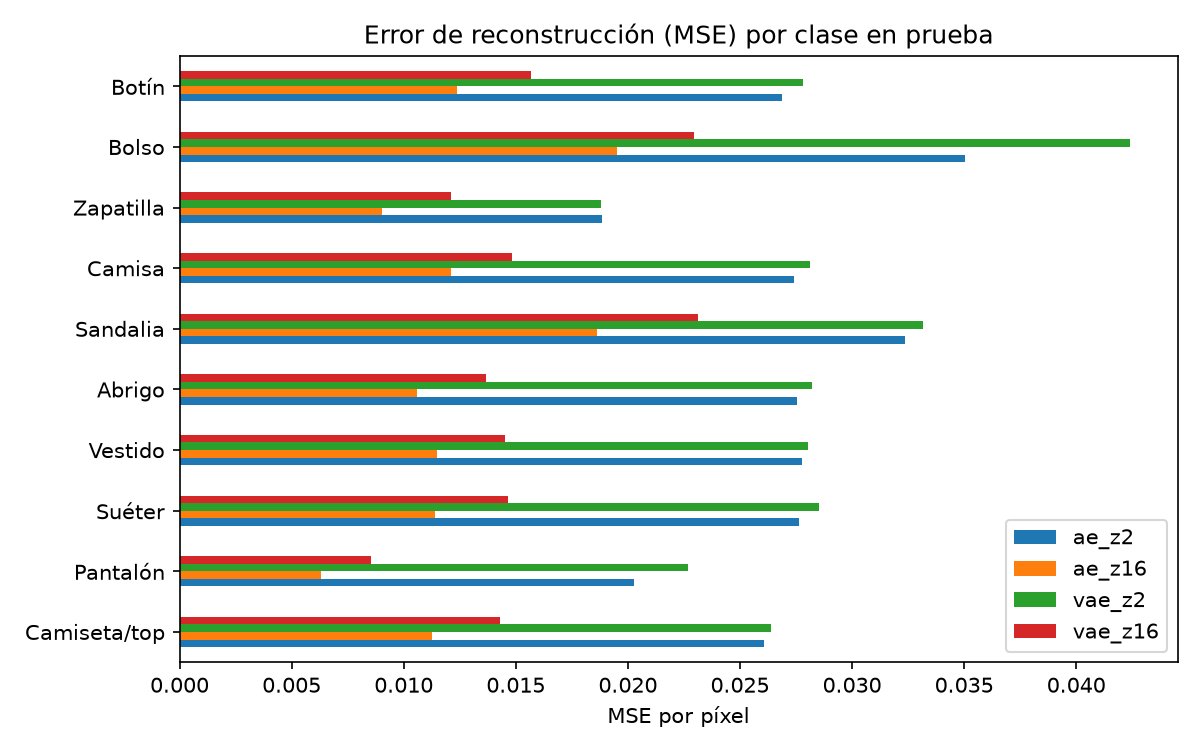

In [5]:
display(results["reconstruction"].round(4))
display(Image(REPORTS / "fig_reconstructions.png", width=900))
display(Image(REPORTS / "fig_reconstruction_per_class.png", width=650))

## 4. Muestreo, interpolación y espacio latente

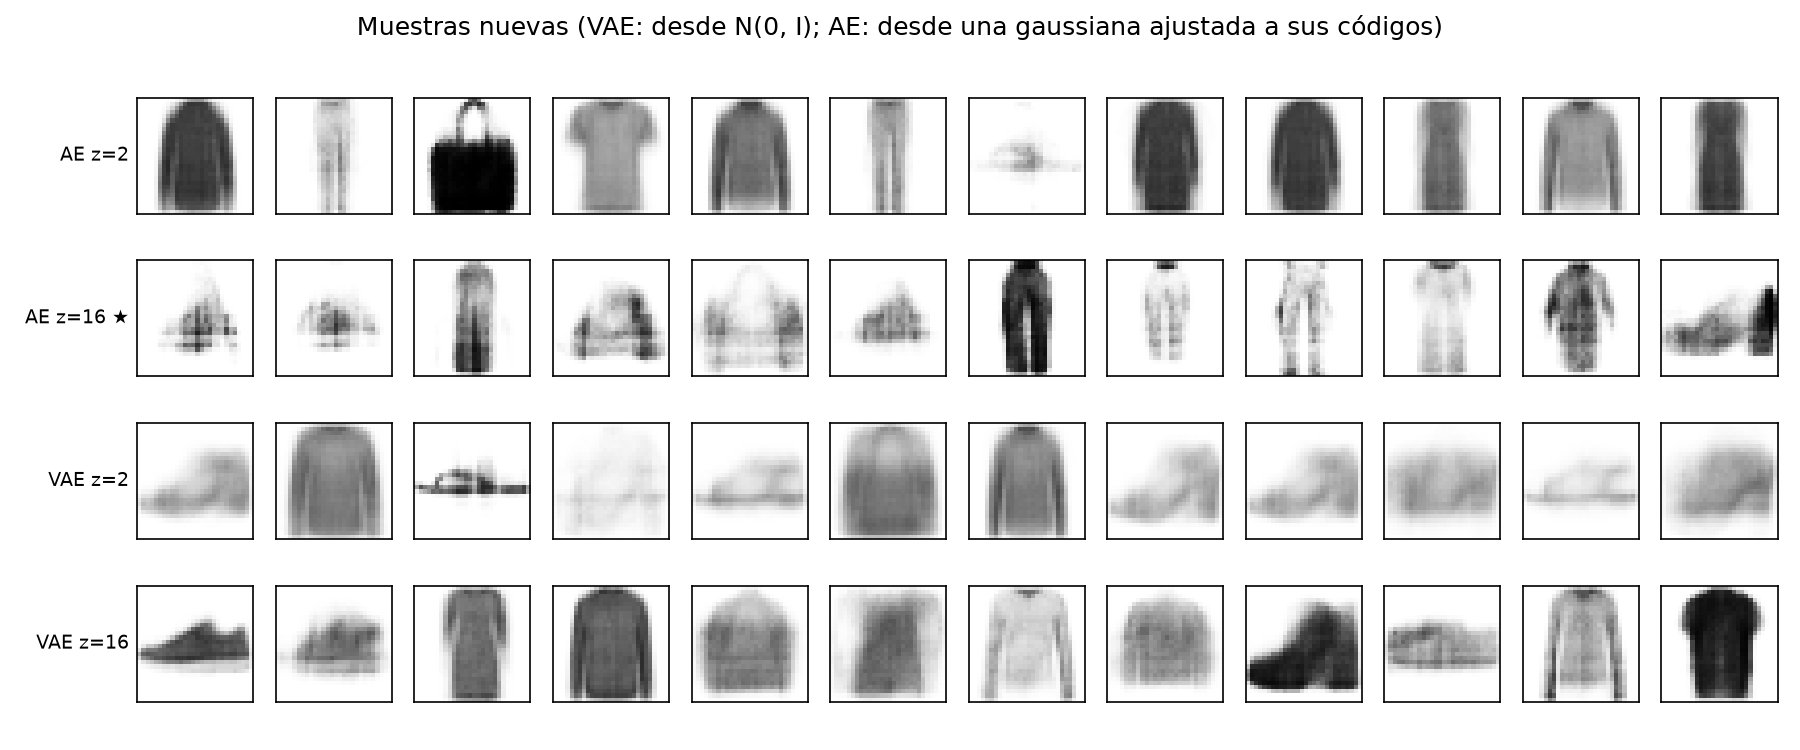

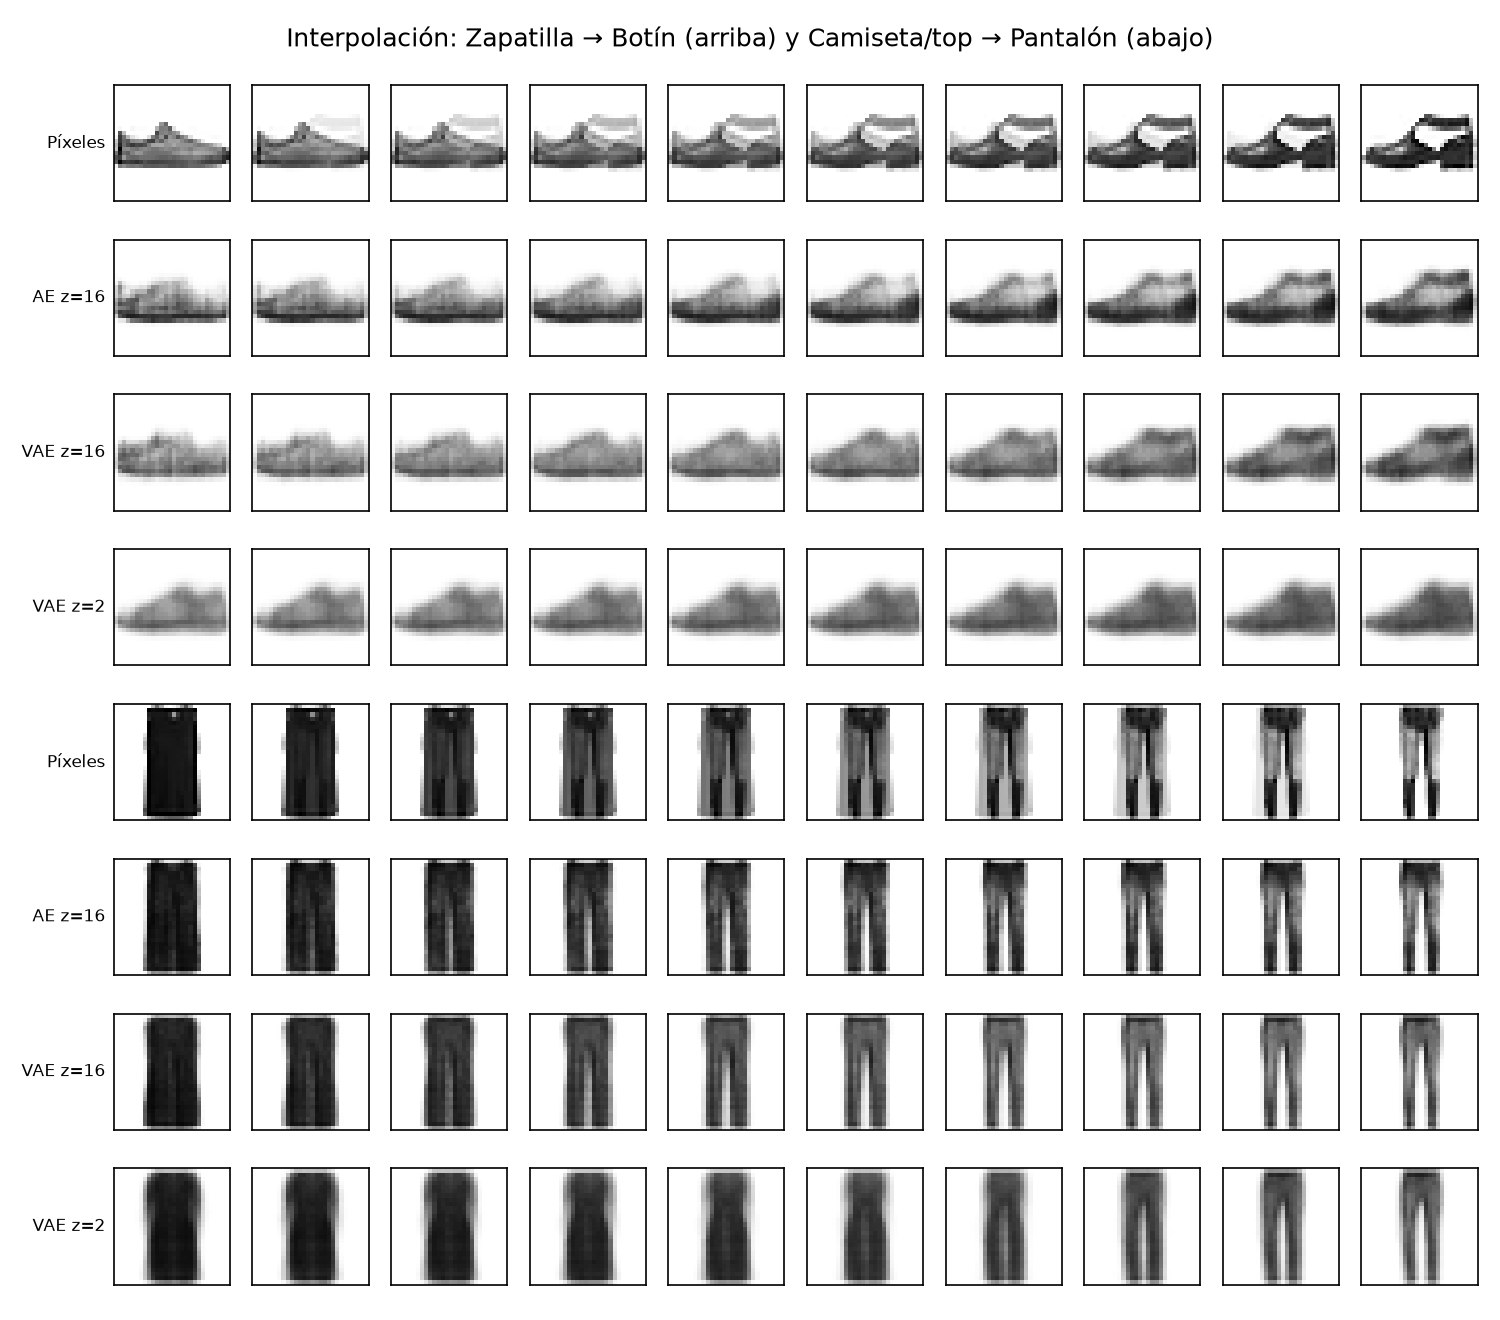

,pair,path,mean_confidence
0,Zapatilla -> Botín,Píxeles,0.722
1,Zapatilla -> Botín,AE z=16,0.668
2,Zapatilla -> Botín,VAE z=16,0.680
3,Zapatilla -> Botín,VAE z=2,0.698
4,Camiseta/top -> Pantalón,Píxeles,0.803
5,Camiseta/top -> Pantalón,AE z=16,0.875
6,Camiseta/top -> Pantalón,VAE z=16,0.836
7,Camiseta/top -> Pantalón,VAE z=2,0.713


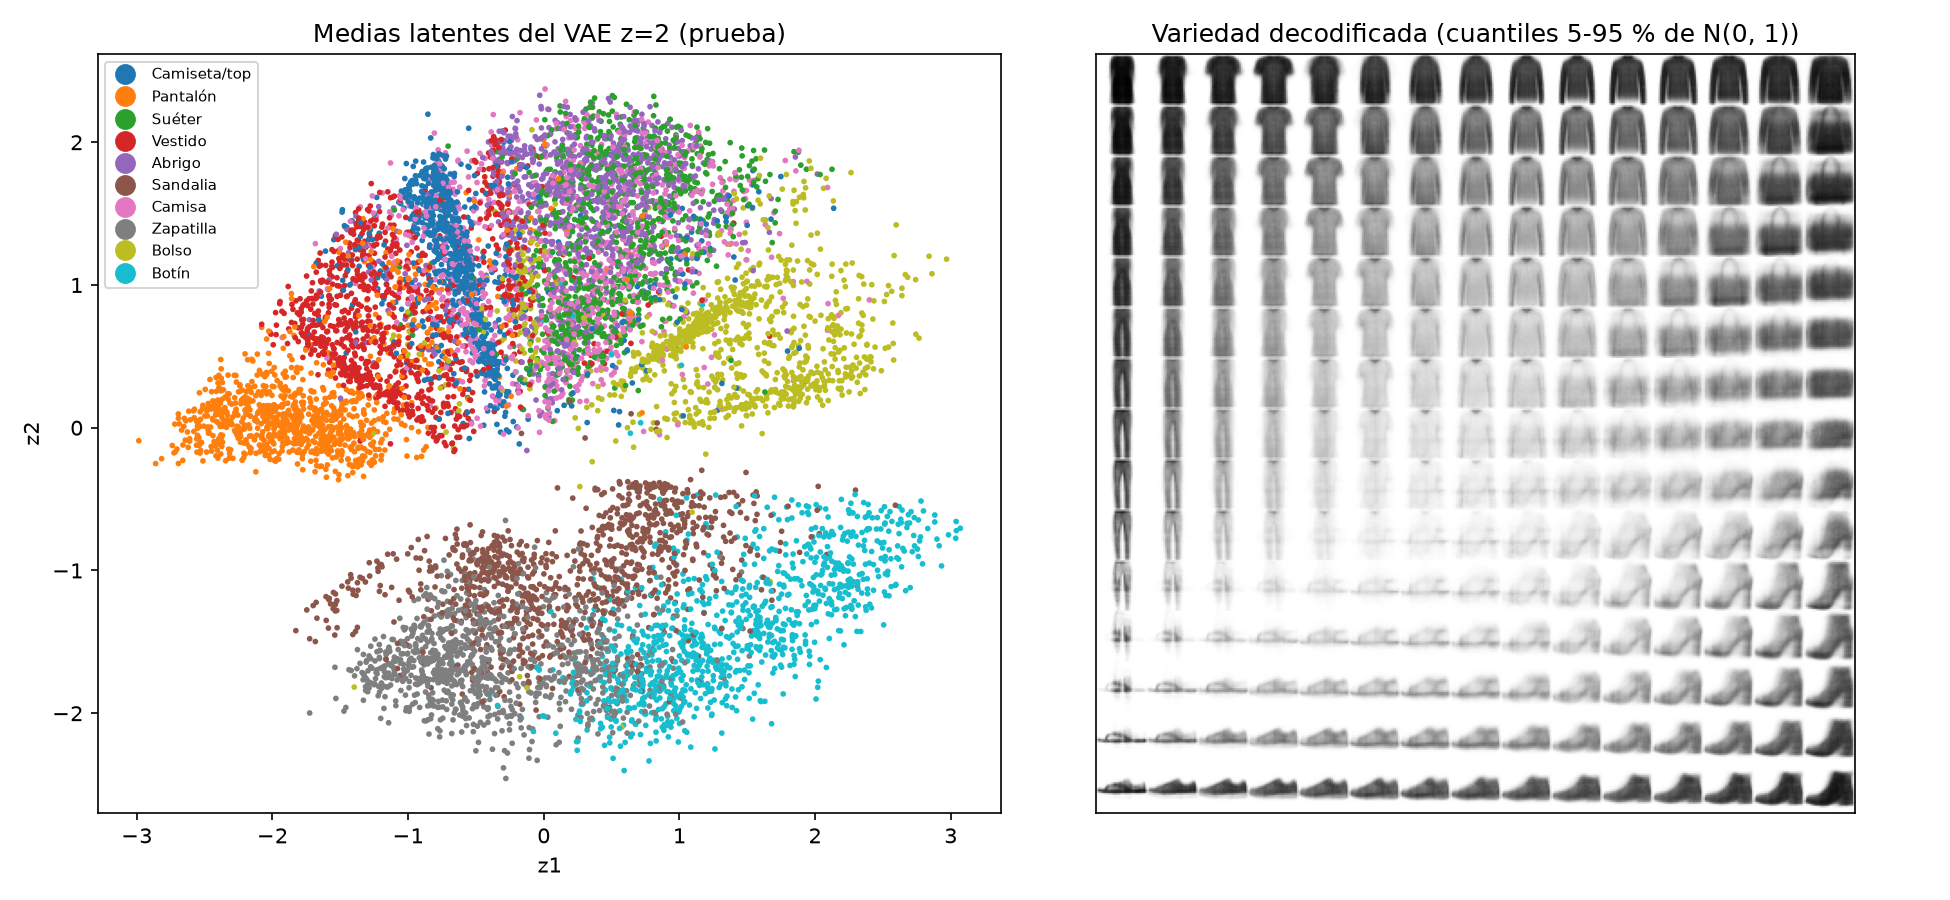

In [6]:
display(Image(REPORTS / "fig_samples.png", width=950))
display(Image(REPORTS / "fig_interpolation.png", width=850))
display(pd.read_csv(REPORTS / "interpolation_confidence.csv").round(3))
display(Image(REPORTS / "fig_latent_space.png", width=950))

## 5. Fidelidad, diversidad y memoria

,model,fd_valid,fd_test,precision,recall,class_entropy,mean_confidence,nn_train_median,share_closer_than_real_p1,generation_ms_per_image,selected
0,real (validación vs. prueba),0.1411,NaN,0.9462,0.9502,0.9958,0.8978,0.1236,0.0100,NaN,False
1,ae_z2,73.3772,73.5622,0.7686,0.0408,0.9165,0.6294,0.0948,0.0195,0.1787,False
2,ae_z16,34.9453,35.0512,0.6956,0.5426,0.9421,0.6606,0.1543,0.0005,0.1770,True
3,vae_z2,97.1141,97.3061,0.5980,0.0060,0.8854,0.5830,0.0929,0.0315,0.0216,False
4,vae_z16,57.8912,57.7723,0.7266,0.3596,0.9521,0.6474,0.1191,0.0015,0.0202,False


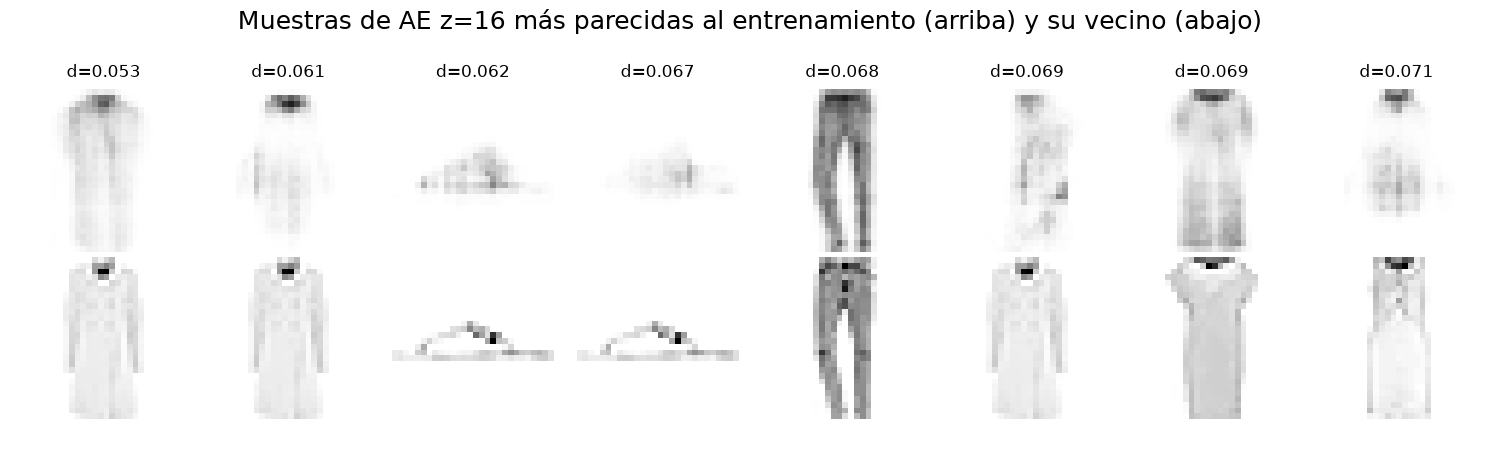

In [7]:
cols = ["model", "fd_valid", "fd_test", "precision", "recall", "class_entropy", "mean_confidence",
        "nn_train_median", "share_closer_than_real_p1", "generation_ms_per_image", "selected"]
display(results["generation"][cols].round(4))
display(Image(REPORTS / "fig_memorization.png", width=850))

**Cómo leer la tabla.** La fila *real* compara imágenes reales de validación y de prueba: es la mejor puntuación alcanzable (distancia de Fréchet cercana a 0, precisión y recall cercanos a 1). *Precisión* mide si las muestras parecen prendas reales (fidelidad); *recall* mide qué parte de la variedad real cubren (diversidad). La memoria compara la distancia de cada muestra a su imagen de entrenamiento más parecida con la de imágenes reales nunca vistas: si las muestras estuvieran mucho más cerca, serían copias.

## 6. Model Card
Las tablas de `MODEL_CARD.md` se regeneran con esta ejecución.

In [8]:
print(json.dumps(results["environment"], indent=2))

{
  "python": "3.12.13",
  "platform": "Linux-6.18.44-fc-v77-x86_64-with-glibc2.39",
  "processor": "x86_64",
  "cpu_count": 1,
  "tensorflow": "2.21.0",
  "gpu": [],
  "numpy": "2.5.3"
}
